In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Paths
DATA_DIR = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Show all columns when printing
pd.set_option("display.max_columns", 50)

In [2]:
# Load data
train = pd.read_csv(DATA_DIR / "train.csv")
demo = pd.read_csv(DATA_DIR / "train_demographics.csv")

thm_cols = [c for c in train.columns if c.startswith("thm_")]
tof_cols = [c for c in train.columns if c.startswith("tof_")]
tof_sensor_cols = {
    f"tof_{i}": [c for c in tof_cols if c.startswith(f"tof_{i}_")]
    for i in range(1, 6)
}

seq = (
    train.groupby("sequence_id")
    .agg(
        subject=("subject", "first"),
        gesture=("gesture", "first"),
        sequence_type=("sequence_type", "first"),
        orientation=("orientation", "first"),
        length=("sequence_counter", "size"),
    )
    .reset_index()
    .merge(demo, on="subject", how="left")
)

In [3]:
# 1a. Summary statistics of raw thermal values (°C)
thm_stats = train[thm_cols].describe(percentiles=[0.5, 0.95, 0.99]).T
print("Raw thermal sensor summary (°C):")
print(thm_stats[["count", "mean", "std", "min", "50%", "95%", "99%", "max"]].round(2), "\n")

# 1b. Initial baseline temperature (first 5 steps) across subjects
first_steps = train[train["sequence_counter"] < 5]
subj_baseline = first_steps.groupby("subject")[thm_cols].mean().dropna(how="all")

print("Subject baseline temperature summary at sequence start (°C):")
print(subj_baseline.describe().T[["min", "25%", "50%", "75%", "max", "std"]].round(2))

Raw thermal sensor summary (°C):
          count   mean   std    min    50%    95%    99%    max
thm_1  567958.0  27.08  3.23  -0.37  26.98  31.58  32.67  38.46
thm_2  567307.0  27.13  2.94  21.96  26.35  32.36  33.38  37.58
thm_3  568473.0  26.70  4.12   0.00  26.96  31.14  32.32  37.29
thm_4  568721.0  27.56  2.25  22.38  27.74  31.04  32.76  39.59
thm_5  541659.0  26.67  2.44  22.05  26.19  30.96  32.45  37.68 

Subject baseline temperature summary at sequence start (°C):
         min    25%    50%    75%    max   std
thm_1   4.90  25.81  26.32  26.72  28.56  2.52
thm_2  23.86  25.27  25.75  26.30  28.45  0.88
thm_3   0.00  25.42  25.95  26.33  28.33  3.00
thm_4  25.08  26.49  26.95  27.51  31.99  1.04
thm_5  24.09  25.75  26.31  26.79  32.68  1.14


In [4]:
# 1c. Temperature change from sequence start to Gesture phase
start_thm = (
    train[train["sequence_counter"] < 5]
    .groupby("sequence_id")[thm_cols]
    .mean()
)
gest_thm = (
    train[train["phase"] == "Gesture"]
    .groupby("sequence_id")[thm_cols]
    .mean()
)

delta_thm = (gest_thm - start_thm).dropna(how="all")
delta_thm["max_delta_thm"] = delta_thm[thm_cols].max(axis=1)
delta_thm["min_delta_thm"] = delta_thm[thm_cols].min(axis=1)

seq_thm = seq.merge(delta_thm, on="sequence_id", how="inner")

# Mean temperature change (°C) per channel for each gesture
seq_thm.groupby(["sequence_type", "gesture"])[
    thm_cols + ["max_delta_thm", "min_delta_thm"]
].mean().round(2)

thm_1  thm_2  thm_3  \
sequence_type gesture                                                           
Non-Target    Drink from bottle/cup                        1.08  -0.07   2.15   
              Feel around in tray and pull out an object   0.04  -0.35   0.09   
              Glasses on/off                               1.76   1.50   2.19   
              Pinch knee/leg skin                          2.43   3.24   2.75   
              Pull air toward your face                   -0.68  -0.53  -0.34   
              Scratch knee/leg skin                        2.57   3.45   2.74   
              Text on phone                                1.51   0.90   1.65   
              Wave hello                                  -0.79  -0.77  -0.47   
              Write name in air                           -0.58  -0.51  -0.21   
              Write name on leg                            2.54   3.47   2.92   
Target        Above ear - pull hair                        2.08   4.14   2.91   
              Cheek - pinch skin                           2.28   2.87   3.07   
              Eyebrow - pull hair                          2.46   3.35   2.93   
              Eyelash - pull hair                          1.67   2.43   2.52   
              Forehead - pull hairline                     3.42   4.01   3.17   
              Forehead - scratch                           3.99   5.36   3.06   
              Neck - pinch skin                            1.73   2.62   2.59   
              Neck - scratch                               2.16   2.88   2.88   

                                                          thm_4  thm_5  \
sequence_type gesture                                                    
Non-Target    Drink from bottle/cup                        1.01  -0.09   
              Feel around in tray and pull out an object   0.32  -0.72   
              Glasses on/off                               1.13   0.54   
              Pinch knee/leg skin                          1.16   1.77   
              Pull air toward your face                   -0.82  -0.93   
              Scratch knee/leg skin                        1.30   1.94   
              Text on phone                                1.42   1.31   
              Wave hello                                  -1.01  -1.05   
              Write name in air                           -0.52  -0.96   
              Write name on leg                            1.30   1.57   
Target        Above ear - pull hair                        0.54   0.56   
              Cheek - pinch skin                           1.48   0.99   
              Eyebrow - pull hair                          1.42   0.92   
              Eyelash - pull hair                          0.99   0.46   
              Forehead - pull hairline                     2.01   1.47   
              Forehead - scratch                           2.33   2.52   
              Neck - pinch skin                            0.74   0.66   
              Neck - scratch                               1.13   1.08   

                                                          max_delta_thm  \
sequence_type gesture                                                     
Non-Target    Drink from bottle/cup                                2.64   
              Feel around in tray and pull out an object           0.99   
              Glasses on/off                                       2.66   
              Pinch knee/leg skin                                  3.93   
              Pull air toward your face                            0.32   
              Scratch knee/leg skin                                4.02   
              Text on phone                                        2.63   
              Wave hello                                           0.26   
              Write name in air                                    0.45   
              Write name on leg                                    3.93   
Target        Above ear - pull hair                     

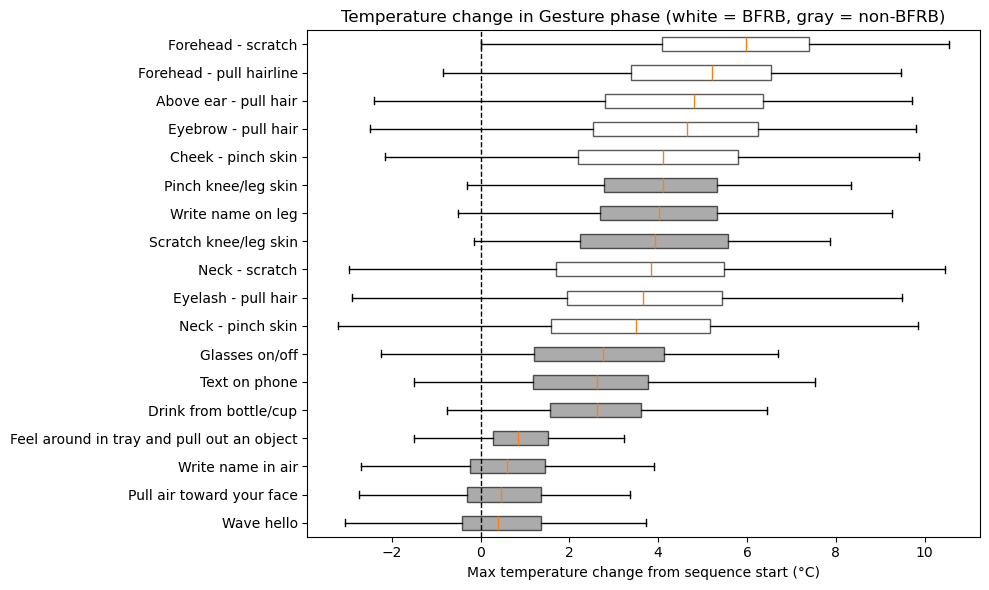

In [5]:
# 1d. Boxplot of max temperature change during Gesture phase by gesture
order = seq_thm.groupby("gesture")["max_delta_thm"].median().sort_values().index

colors = [
    "white" if seq_thm.loc[seq_thm["gesture"] == g, "sequence_type"].iloc[0] == "Target"
    else "tab:gray"
    for g in order
]

fig, ax = plt.subplots(figsize=(10, 6))

bp = ax.boxplot(
    [seq_thm.loc[seq_thm["gesture"] == g, "max_delta_thm"].dropna() for g in order],
    vert=False,
    showfliers=False,
    patch_artist=True,
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order)
ax.set_xlabel("Max temperature change from sequence start (°C)")
ax.set_title("Temperature change in Gesture phase (white = BFRB, gray = non-BFRB)")

plt.tight_layout()
plt.savefig(FIG_DIR / "thm_delta_by_gesture.png", dpi=150)
plt.show()

In [ ]:
# 1e. Investigate the gap between normal readings (>= 21.96 °C in thm_2/4/5) and near-zero readings
for c in thm_cols:
    low_vals = train[c][train[c] < 22.0]
    if len(low_vals) > 0:
        print(f"{c}: {len(low_vals)} rows < 22.0 °C | min = {low_vals.min():.2f}, max = {low_vals.max():.2f}")
    else:
        print(f"{c}: 0 rows < 22.0 °C")


thm_1: 4310 rows < 22.0 °C | min = -0.37, max = 18.94
thm_2: 2 rows < 22.0 °C | min = 21.96, max = 21.98
thm_3: 8675 rows < 22.0 °C | min = 0.00, max = 21.95
thm_4: 0 rows < 22.0 °C
thm_5: 0 rows < 22.0 °C


In [30]:
# 1e-2. Inspect sequences and gestures with mean temperature < 20.0 °C across the entire sequence
seq_means = (
    train.groupby(["sequence_id", "subject", "sequence_type", "gesture"])[thm_cols]
    .mean()
    .reset_index()
)
seq_maxs = train.groupby("sequence_id")[thm_cols].max().reset_index()

# Filter sequences where at least one thermal channel has a mean < 20.0 °C
low_seq = seq_means[(seq_means[thm_cols] < 20.0).any(axis=1)].copy()

print(f"Total sequences with at least one thermal channel mean < 20.0 °C: {len(low_seq)} / {len(seq_means)}\n")

# 1. Breakdown by thermal sensor
for c in thm_cols:
    n_mean_low = (seq_means[c] < 20.0).sum()
    n_all_low = (seq_maxs[c] < 20.0).sum()  # Never reaches 20.0 °C throughout the entire sequence
    if n_mean_low > 0 or n_all_low > 0:
        print(f"- {c}: {n_mean_low} sequences with mean < 20.0 °C ({n_all_low} sequences with max < 20.0 °C throughout)")

# 2. Breakdown by gesture and subject
print("\nBreakdown by gesture and subject:")
gesture_low_summary = (
    low_seq.groupby(["sequence_type", "gesture"])
    .agg(
        n_sequences=("sequence_id", "count"),
        n_subjects=("subject", "nunique"),
        subjects=("subject", lambda x: list(x.unique())),
        thm_1_mean=("thm_1", "mean"),
        thm_3_mean=("thm_3", "mean"),
    )
    .reset_index()
)
display(gesture_low_summary.round(2))

# 3. Check variation (max - min) within those low-temperature sequences (flatline vs active signal)
for c in ["thm_1", "thm_3"]:
    bad_ids = seq_means.loc[seq_means[c] < 20.0, "sequence_id"]
    if len(bad_ids) > 0:
        sub_df = train[train["sequence_id"].isin(bad_ids)]
        grp = (
            sub_df.groupby(["sequence_id", "subject", "gesture"])[c]
            .agg(["min", "mean", "max", "std"])
            .reset_index()
        )
        grp["range"] = grp["max"] - grp["min"]
        print(f"\nVariation details for {c} in sequences with mean < 20.0 °C:")
        display(grp.round(3))

Total sequences with at least one thermal channel mean < 20.0 °C: 153 / 8151

- thm_1: 51 sequences with mean < 20.0 °C (51 sequences with max < 20.0 °C throughout)
- thm_3: 102 sequences with mean < 20.0 °C (102 sequences with max < 20.0 °C throughout)

Breakdown by gesture and subject:


,sequence_type,gesture,n_sequences,n_subjects,subjects,thm_1_mean,thm_3_mean
0,Non-Target,Drink from bottle/cup,3,2,"[SUBJ_028998, SUBJ_036405]",22.22,8.46
1,Non-Target,Feel around in tray and pull out an object,3,2,"[SUBJ_028998, SUBJ_036405]",22.79,8.34
2,Non-Target,Glasses on/off,3,2,"[SUBJ_028998, SUBJ_036405]",23.28,9.31
3,Non-Target,Pinch knee/leg skin,3,2,"[SUBJ_028998, SUBJ_036405]",20.91,9.35
4,Non-Target,Pull air toward your face,9,2,"[SUBJ_028998, SUBJ_036405]",16.73,8.33
5,Non-Target,Scratch knee/leg skin,3,2,"[SUBJ_028998, SUBJ_036405]",20.93,9.65
6,Non-Target,Text on phone,12,2,"[SUBJ_036405, SUBJ_028998]",19.92,8.69
7,Non-Target,Wave hello,9,2,"[SUBJ_028998, SUBJ_036405]",16.67,8.14
8,Non-Target,Write name in air,9,2,"[SUBJ_028998, SUBJ_036405]",16.67,8.27
9,Non-Target,Write name on leg,3,2,"[SUBJ_028998, SUBJ_036405]",21.24,9.88



Variation details for thm_1 in sequences with mean < 20.0 °C:


,sequence_id,subject,gesture,min,mean,max,std,range
0,SEQ_001763,SUBJ_036405,Neck - scratch,2.109,3.111,3.785,0.608,1.676
1,SEQ_002384,SUBJ_036405,Forehead - pull hairline,1.960,3.828,4.653,0.877,2.694
2,SEQ_008762,SUBJ_036405,Text on phone,14.705,15.834,16.542,0.594,1.837
3,SEQ_010076,SUBJ_036405,Neck - pinch skin,-0.062,0.617,1.730,0.496,1.792
4,SEQ_010765,SUBJ_036405,Cheek - pinch skin,14.450,15.950,17.852,0.975,3.402
5,SEQ_011781,SUBJ_036405,Forehead - pull hairline,-0.118,2.398,4.456,1.604,4.573
6,SEQ_015611,SUBJ_036405,Eyelash - pull hair,14.685,17.221,18.805,1.279,4.120
7,SEQ_016162,SUBJ_036405,Pull air toward your face,-0.166,0.047,0.668,0.203,0.834
8,SEQ_017783,SUBJ_036405,Above ear - pull hair,0.646,2.549,3.688,0.861,3.042
9,SEQ_018408,SUBJ_036405,Above ear - pull hair,14.526,16.553,18.044,1.299,3.518



Variation details for thm_3 in sequences with mean < 20.0 °C:


,sequence_id,subject,gesture,min,mean,max,std,range
0,SEQ_001118,SUBJ_028998,Above ear - pull hair,0.0,0.0,0.0,0.0,0.0
1,SEQ_002591,SUBJ_028998,Neck - pinch skin,0.0,0.0,0.0,0.0,0.0
2,SEQ_002826,SUBJ_028998,Eyelash - pull hair,0.0,0.0,0.0,0.0,0.0
3,SEQ_003297,SUBJ_028998,Pinch knee/leg skin,0.0,0.0,0.0,0.0,0.0
4,SEQ_003776,SUBJ_028998,Forehead - scratch,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
97,SEQ_063351,SUBJ_028998,Above ear - pull hair,0.0,0.0,0.0,0.0,0.0
98,SEQ_063408,SUBJ_028998,Text on phone,0.0,0.0,0.0,0.0,0.0
99,SEQ_064042,SUBJ_028998,Write name in air,0.0,0.0,0.0,0.0,0.0
100,SEQ_064138,SUBJ_028998,Cheek - pinch skin,0.0,0.0,0.0,0.0,0.0


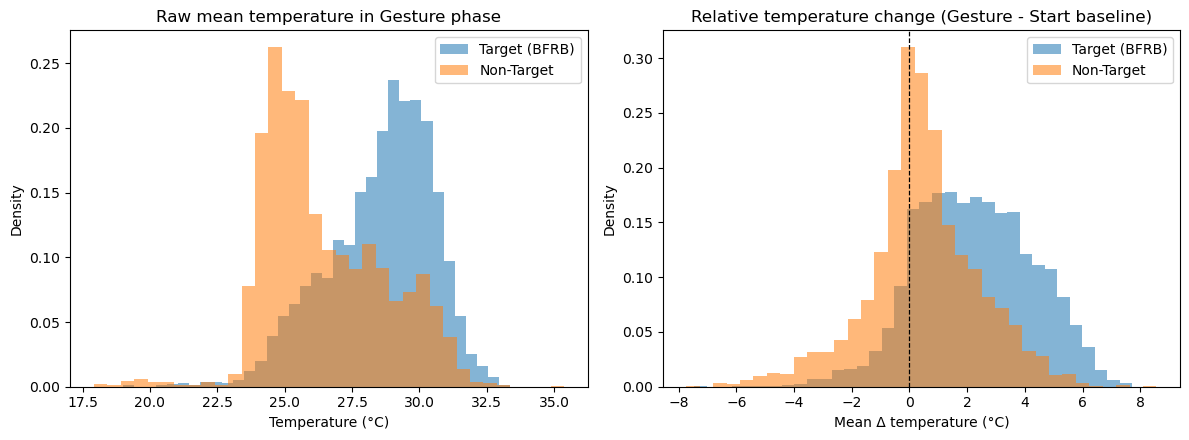

In [7]:
# 1f. Compare raw Gesture temperature vs baseline-subtracted temperature (Target vs Non-Target)
gest_raw_thm = (
    train[train["phase"] == "Gesture"]
    .groupby("sequence_id")[thm_cols]
    .mean()
)
gest_raw_thm["raw_mean_thm"] = gest_raw_thm.mean(axis=1)
seq_thm_comp = seq_thm.merge(gest_raw_thm[["raw_mean_thm"]], on="sequence_id", how="inner")
seq_thm_comp["mean_delta_thm"] = seq_thm_comp[thm_cols].mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for seq_type, color, label in [
    ("Target", "tab:blue", "Target (BFRB)"),
    ("Non-Target", "tab:orange", "Non-Target"),
]:
    sub = seq_thm_comp[seq_thm_comp["sequence_type"] == seq_type]
    axes[0].hist(sub["raw_mean_thm"].dropna(), bins=35, density=True, alpha=0.55, color=color, label=label)
    axes[1].hist(sub["mean_delta_thm"].dropna(), bins=35, density=True, alpha=0.55, color=color, label=label)

axes[0].set_title("Raw mean temperature in Gesture phase")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Density")
axes[0].legend()

axes[1].axvline(0, color="k", linestyle="--", linewidth=0.9)
axes[1].set_title("Relative temperature change (Gesture - Start baseline)")
axes[1].set_xlabel("Mean Δ temperature (°C)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "thm_raw_vs_delta_hist.png", dpi=150)
plt.show()

## Tổng kết: cảm biến nhiệt
- Nhiệt độ bình thường nằm trong khoảng 22–39,6 °C; ngoại trừ `thm_1` (min -0,37 °C) và `thm_3` (min 0,00 °C) có một số giá trị ngoại lai dưới 22 °C.
- Nhiệt độ nền ở đầu chuỗi (5 bước đầu) chênh lệch khá lớn giữa các người đeo (~24–32,7 °C).
- Độ tăng nhiệt độ từ đầu chuỗi đến pha cử chỉ (`delta_thm`) tách biệt rõ các nhóm cử chỉ:
  - Cử chỉ trên không (*Wave hello*, *Write name in air*, *Pull air toward your face*) có nhiệt độ giảm nhẹ (-0,5 đến -1,0 °C).
  - 8 cử chỉ BFRB và 3 cử chỉ chạm chân đều có nhiệt độ tăng mạnh (+3,5 đến +5,6 °C).
  - Chạm chân làm nóng cả 5 cảm biến (kể cả `thm_5`), trong khi BFRB vùng mặt/cổ/tai làm nóng mạnh `thm_1..3` hơn `thm_4..5`.

In [8]:
# 2a. Distribution of valid ToF distances (excluding -1 and NaN) and active pixel count per row
tof_dist_rows = []
active_counts = pd.DataFrame(index=train.index)

for i in range(1, 6):
    name = f"tof_{i}"
    arr = train[tof_sensor_cols[name]].to_numpy(dtype=np.float32)
    valid_mask = (~np.isnan(arr)) & (arr != -1)
    
    # Count how many pixels (out of 64) detect an object at each time step
    active_counts[name] = valid_mask.sum(axis=1)
    
    measured = arr[valid_mask]
    q10, q25, q50, q75, q90, q99 = np.percentile(measured, [10, 25, 50, 75, 90, 99])
    tof_dist_rows.append({
        "sensor": name,
        "mean": float(measured.mean()),
        "std": float(measured.std()),
        "10%": q10, "25%": q25, "50%": q50, "75%": q75, "90%": q90, "99%": q99
    })

print("Measured ToF distance percentiles (mm, excluding -1):")
display(pd.DataFrame(tof_dist_rows).round(1))

print("Number of active pixels (out of 64) per row:")
display(active_counts.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).
        T[["mean", "std", "min", "25%", "50%", "75%", "90%", "max"]].round(1))

Measured ToF distance percentiles (mm, excluding -1):


,sensor,mean,std,10%,25%,50%,75%,90%,99%
0,tof_1,111.8,62.3,34.0,62.0,104.0,156.0,205.0,245.0
1,tof_2,101.7,58.2,36.0,60.0,90.0,134.0,195.0,243.0
2,tof_3,105.3,63.0,27.0,55.0,98.0,149.0,200.0,244.0
3,tof_4,112.4,65.1,28.0,60.0,108.0,162.0,206.0,245.0
4,tof_5,109.9,66.0,26.0,56.0,103.0,160.0,208.0,245.0


Number of active pixels (out of 64) per row:


,mean,std,min,25%,50%,75%,90%,max
tof_1,26.4,21.6,0.0,3.0,26.0,46.0,57.0,64.0
tof_2,23.7,20.7,0.0,2.0,21.0,42.0,55.0,64.0
tof_3,25.5,22.0,0.0,1.0,24.0,45.0,57.0,64.0
tof_4,30.5,21.8,0.0,9.0,31.0,51.0,61.0,64.0
tof_5,23.8,21.1,0.0,2.0,21.0,42.0,56.0,64.0


In [9]:
# 2b. Breakdown of 8x8 grid states across all rows in train
state_rows = []
for i in range(1, 6):
    name = f"tof_{i}"
    arr = train[tof_sensor_cols[name]].to_numpy(dtype=np.float32)
    
    n_nan = np.isnan(arr).sum(axis=1)
    n_neg1 = (arr == -1).sum(axis=1)
    n_valid = 64 - n_nan - n_neg1
    
    state_rows.append({
        "sensor": name,
        "all_NaN (broken)": (n_nan == 64).mean(),
        "all_-1 (no object)": (n_neg1 == 64).mean(),
        "mixed (-1 and object)": ((n_valid > 0) & (n_neg1 > 0)).mean(),
        "all_valid (64/64 pixels)": (n_valid == 64).mean(),
    })

state_df = pd.DataFrame(state_rows).set_index("sensor")
(state_df * 100).round(2)

,all_NaN (broken),all_-1 (no object),mixed (-1 and object),all_valid (64/64 pixels)
sensor,,,,
tof_1,1.08,18.83,78.06,2.02
tof_2,1.08,21.34,76.62,0.96
tof_3,1.08,22.41,74.05,2.45
tof_4,1.08,9.55,84.69,4.68
tof_5,5.24,16.75,75.59,2.41


In [10]:
# 2c. Active pixel ratio and object distance (excluding -1) across behavior phases
tof_feat = train[["sequence_id", "sequence_counter", "phase", "gesture", "sequence_type"]].copy()

active_cols = [f"tof_{i}_active" for i in range(1, 6)]
mean_cols = [f"tof_{i}_mean" for i in range(1, 6)]
min_cols = [f"tof_{i}_min" for i in range(1, 6)]

for i in range(1, 6):
    cols = tof_sensor_cols[f"tof_{i}"]
    valid_df = train[cols].replace(-1, np.nan)
    
    tof_feat[f"tof_{i}_active"] = valid_df.notna().mean(axis=1)
    tof_feat[f"tof_{i}_mean"] = valid_df.mean(axis=1)
    tof_feat[f"tof_{i}_min"] = valid_df.min(axis=1)

print("Mean active pixel fraction (0..1) across phases:")
display(tof_feat.groupby(["sequence_type", "phase"])[active_cols].mean().round(2))

print("Mean object distance (mm, excluding -1) across phases:")
display(tof_feat.groupby(["sequence_type", "phase"])[mean_cols].mean().round(1))

print("Mean nearest-object distance (mm, excluding -1) across phases:")
display(tof_feat.groupby(["sequence_type", "phase"])[min_cols].mean().round(1))

Mean active pixel fraction (0..1) across phases:


tof_1_active  tof_2_active  tof_3_active  \
sequence_type phase                                                  
Non-Target    Gesture             0.32          0.26          0.32   
              Transition          0.28          0.24          0.23   
Target        Gesture             0.61          0.58          0.64   
              Transition          0.39          0.34          0.35   

                          tof_4_active  tof_5_active  
sequence_type phase                                   
Non-Target    Gesture             0.39          0.29  
              Transition          0.38          0.33  
Target        Gesture             0.63          0.45  
              Transition          0.46          0.38

Mean object distance (mm, excluding -1) across phases:


tof_1_mean  tof_2_mean  tof_3_mean  tof_4_mean  \
sequence_type phase                                                        
Non-Target    Gesture          142.4       130.8       150.6       128.3   
              Transition       147.7       139.6       154.2       138.8   
Target        Gesture          112.5       100.9        98.6       113.8   
              Transition       133.8       126.1       127.3       133.1   

                          tof_5_mean  
sequence_type phase                   
Non-Target    Gesture          126.9  
              Transition       129.1  
Target        Gesture          124.6  
              Transition       129.9

Mean nearest-object distance (mm, excluding -1) across phases:


tof_1_min  tof_2_min  tof_3_min  tof_4_min  \
sequence_type phase                                                    
Non-Target    Gesture         100.9       89.9      105.4       85.1   
              Transition      105.9       98.8      112.6       96.2   
Target        Gesture          68.1       64.4       58.6       67.2   
              Transition       91.8       88.7       88.0       89.1   

                          tof_5_min  
sequence_type phase                  
Non-Target    Gesture          87.6  
              Transition       88.8  
Target        Gesture          76.1  
              Transition       87.1

In [11]:
# 2d. Active pixel fraction and object distance by gesture (Gesture phase)
gest_tof = tof_feat[tof_feat["phase"] == "Gesture"]

seq_tof = (
    gest_tof.groupby(["sequence_type", "gesture", "sequence_id"])[
        active_cols + mean_cols + min_cols
    ]
    .mean()
    .reset_index()
)

print("Mean active pixel fraction (0..1) by gesture:")
display(seq_tof.groupby(["sequence_type", "gesture"])[active_cols].mean().round(2))

print("Mean object distance (mm, excluding -1) by gesture:")
display(seq_tof.groupby(["sequence_type", "gesture"])[mean_cols].mean().round(1))

Mean active pixel fraction (0..1) by gesture:


tof_1_active  \
sequence_type gesture                                                    
Non-Target    Drink from bottle/cup                               0.31   
              Feel around in tray and pull out an object          0.17   
              Glasses on/off                                      0.42   
              Pinch knee/leg skin                                 0.73   
              Pull air toward your face                           0.08   
              Scratch knee/leg skin                               0.75   
              Text on phone                                       0.55   
              Wave hello                                          0.07   
              Write name in air                                   0.07   
              Write name on leg                                   0.78   
Target        Above ear - pull hair                               0.50   
              Cheek - pinch skin                                  0.66   
              Eyebrow - pull hair                                 0.61   
              Eyelash - pull hair                                 0.55   
              Forehead - pull hairline                            0.66   
              Forehead - scratch                                  0.75   
              Neck - pinch skin                                   0.55   
              Neck - scratch                                      0.60   

                                                          tof_2_active  \
sequence_type gesture                                                    
Non-Target    Drink from bottle/cup                               0.17   
              Feel around in tray and pull out an object          0.28   
              Glasses on/off                                      0.40   
              Pinch knee/leg skin                                 0.66   
              Pull air toward your face                           0.05   
              Scratch knee/leg skin                               0.68   
              Text on phone                                       0.40   
              Wave hello                                          0.04   
              Write name in air                                   0.05   
              Write name on leg                                   0.74   
Target        Above ear - pull hair                               0.62   
              Cheek - pinch skin                                  0.56   
              Eyebrow - pull hair                                 0.57   
              Eyelash - pull hair                                 0.48   
              Forehead - pull hairline                            0.59   
              Forehead - scratch                                  0.75   
              Neck - pinch skin                                   0.53   
              Neck - scratch                                      0.57   

                                                          tof_3_active  \
sequence_type gesture                                                    
Non-Target    Drink from bottle/cup                               0.44   
              Feel around in tray and pull out an object          0.15   
              Glasses on/off                                      0.50   
              Pinch knee/leg skin                                 0.68   
              Pull air toward your face                           0.13   
              Scratch knee/leg skin                               0.72   
              Text on phone                                       0.43   
              Wave hello                                          0.11   
              Write name in air                                   0.11   
              Write name on leg                                   0.72   
Target        Above ear - pull hair                               0.62   
              Cheek - pinch skin                                  0.71   
              Eyebrow - pull hair                           

Mean object distance (mm, excluding -1) by gesture:


tof_1_mean  \
sequence_type gesture                                                  
Non-Target    Drink from bottle/cup                            179.2   
              Feel around in tray and pull out an object       160.4   
              Glasses on/off                                   182.8   
              Pinch knee/leg skin                               78.6   
              Pull air toward your face                        194.6   
              Scratch knee/leg skin                             77.3   
              Text on phone                                    131.6   
              Wave hello                                       190.1   
              Write name in air                                200.1   
              Write name on leg                                 70.8   
Target        Above ear - pull hair                            128.6   
              Cheek - pinch skin                               103.6   
              Eyebrow - pull hair                              138.4   
              Eyelash - pull hair                              132.5   
              Forehead - pull hairline                         128.4   
              Forehead - scratch                               102.8   
              Neck - pinch skin                                 94.9   
              Neck - scratch                                    82.0   

                                                          tof_2_mean  \
sequence_type gesture                                                  
Non-Target    Drink from bottle/cup                            183.1   
              Feel around in tray and pull out an object       116.5   
              Glasses on/off                                   180.4   
              Pinch knee/leg skin                               75.0   
              Pull air toward your face                        154.1   
              Scratch knee/leg skin                             69.1   
              Text on phone                                    137.5   
              Wave hello                                       188.5   
              Write name in air                                130.6   
              Write name on leg                                 67.9   
Target        Above ear - pull hair                            102.9   
              Cheek - pinch skin                               111.7   
              Eyebrow - pull hair                              120.9   
              Eyelash - pull hair                              123.7   
              Forehead - pull hairline                         102.6   
              Forehead - scratch                                78.4   
              Neck - pinch skin                                 92.5   
              Neck - scratch                                    82.1   

                                                          tof_3_mean  \
sequence_type gesture                                                  
Non-Target    Drink from bottle/cup                            157.3   
              Feel around in tray and pull out an object       172.1   
              Glasses on/off                                   160.2   
              Pinch knee/leg skin                              107.6   
              Pull air toward your face                        186.0   
              Scratch knee/leg skin                            107.2   
              Text on phone                                    143.3   
              Wave hello                                       185.0   
              Write name in air                                197.1   
              Write name on leg                                 95.5   
Target        Above ear - pull hair                            111.6   
              Cheek - pinch skin                                80.0   
              Eyebrow - pull hair                              126.4   
              Eyelash - pull hair                              110.2   
              Forehead -

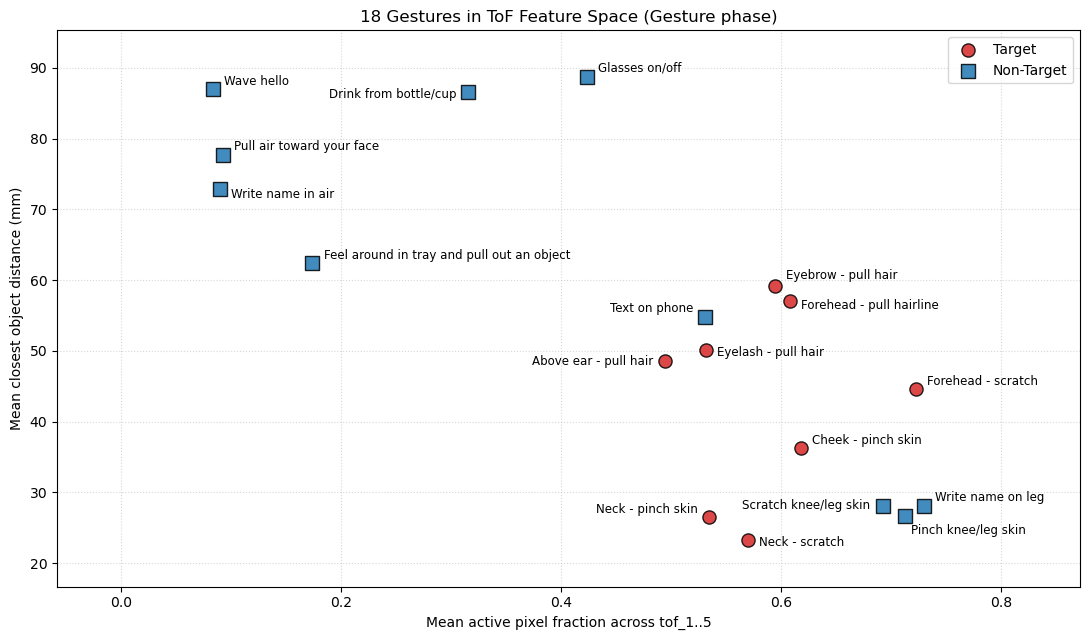

In [ ]:
# 2e. 2D Scatter plot of the 18 gestures in ToF feature space (Active ratio vs Closest distance)
seq_tof["mean_active_all"] = seq_tof[active_cols].mean(axis=1)
seq_tof["min_dist_all"] = seq_tof[min_cols].min(axis=1)

g_summary = (
    seq_tof.groupby(["sequence_type", "gesture"])
    .agg(
        active=("mean_active_all", "mean"),
        min_dist=("min_dist_all", "mean"),
    )
    .reset_index()
)

# Custom (dx, dy, horizontalalignment) for crowded points so labels never overlap
label_offsets = {
    "Drink from bottle/cup": (-8, -4, "right"),
    "Glasses on/off": (8, 4, "left"),
    "Above ear - pull hair": (-8, -3, "right"),
    "Eyelash - pull hair": (8, -4, "left"),
    "Text on phone": (-8, 4, "right"),
    "Eyebrow - pull hair": (8, 5, "left"),
    "Forehead - pull hairline": (8, -6, "left"),
    "Neck - pinch skin": (-8, 3, "right"),
    "Neck - scratch": (8, -4, "left"),
    "Scratch knee/leg skin": (-25, 5, "right"),
    "Pinch knee/leg skin": (20, -20, "left"),
    "Write name on leg": (8, 4, "left"),
    "Write name in air": (8, -6, "left"),
}

fig, ax = plt.subplots(figsize=(11, 6.5))
for seq_type, color, marker in [("Target", "tab:red", "o"), ("Non-Target", "tab:blue", "s")]:
    sub = g_summary[g_summary["sequence_type"] == seq_type]
    ax.scatter(
        sub["active"], sub["min_dist"],
        s=90, color=color, marker=marker, alpha=0.85, label=seq_type, edgecolors="k", zorder=3
    )
    for _, row in sub.iterrows():
        g = row["gesture"]
        dx, dy, ha = label_offsets.get(g, (8, 3, "left"))
        ax.annotate(
            g,
            (row["active"], row["min_dist"]),
            xytext=(dx, dy),
            textcoords="offset points",
            ha=ha,
            fontsize=8.5,
        )

ax.margins(x=0.22, y=0.10)
ax.set_xlabel("Mean active pixel fraction across tof_1..5")
ax.set_ylabel("Mean closest object distance (mm)")
ax.set_title("18 Gestures in ToF Feature Space (Gesture phase)")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "tof_gesture_scatter_2d.png", dpi=150)
plt.show()

Mean active pixel fraction by 4x4 quadrant in Gesture phase:


,Q1 (Top-L),Q2 (Top-R),Q3 (Bot-L),Q4 (Bot-R)
sensor,,,,
tof_1,0.469,0.586,0.419,0.516
tof_2,0.438,0.532,0.387,0.489
tof_3,0.595,0.439,0.574,0.470
tof_4,0.480,0.614,0.483,0.591
tof_5,0.512,0.435,0.339,0.272


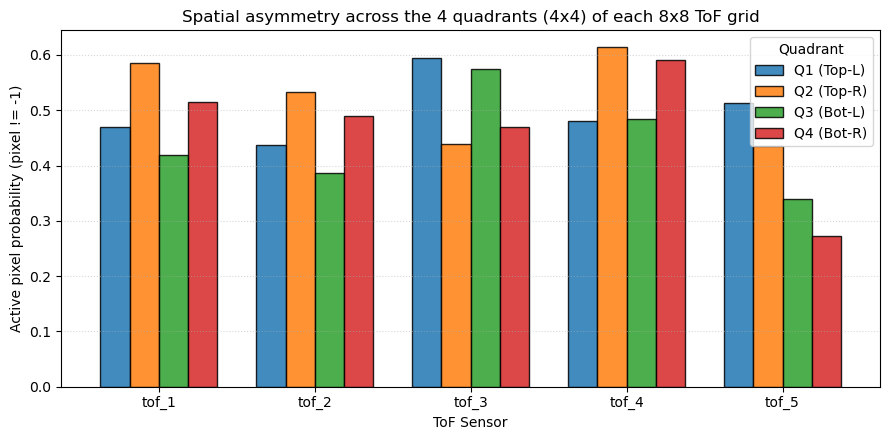

In [13]:
# 2f. Compare active pixel ratio across the 4 quadrants (4x4 sub-grids) of each 8x8 ToF sensor
gest_raw = train[train["phase"] == "Gesture"]
quad_names = ["Q1 (Top-L)", "Q2 (Top-R)", "Q3 (Bot-L)", "Q4 (Bot-R)"]
quad_rows = []

for i in range(1, 6):
    name = f"tof_{i}"
    arr = gest_raw[tof_sensor_cols[name]].to_numpy(dtype=np.float32)
    active_2d = ((~np.isnan(arr)) & (arr != -1)).reshape(-1, 8, 8)
    
    quad_rows.append({
        "sensor": name,
        "Q1 (Top-L)": active_2d[:, :4, :4].mean(),
        "Q2 (Top-R)": active_2d[:, :4, 4:].mean(),
        "Q3 (Bot-L)": active_2d[:, 4:, :4].mean(),
        "Q4 (Bot-R)": active_2d[:, 4:, 4:].mean(),
    })

quad_summary = pd.DataFrame(quad_rows).set_index("sensor")
print("Mean active pixel fraction by 4x4 quadrant in Gesture phase:")
display(quad_summary.round(3))

ax = quad_summary.plot.bar(figsize=(9, 4.5), rot=0, width=0.75, edgecolor="black", alpha=0.85)
ax.set_ylabel("Active pixel probability (pixel != -1)")
ax.set_xlabel("ToF Sensor")
ax.set_title("Spatial asymmetry across the 4 quadrants (4x4) of each 8x8 ToF grid")
ax.legend(title="Quadrant")
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "tof_quadrant_bars.png", dpi=150)
plt.show()

## Tổng kết: cảm biến khoảng cách ToF
- Khi có vật cản (`pixel != -1`), khoảng cách đo được trải từ 0–249 mm (trung vị ~90–108 mm); trung bình mỗi bước thời gian có khoảng 24–30/64 pixel hoạt động.
- Trên toàn tập train, **74–85% số dòng ở trạng thái trộn lẫn (`mixed`)** — tức một phần lưới 8×8 nhìn thấy vật cản, phần còn lại là `-1` (không thấy vật); chỉ có 1–5% số dòng cả 64 pixel đều thấy vật và 10–22% số dòng cả 64 pixel đều là `-1`. Do đó không thể tính trung bình trực tiếp trên giá trị `-1`.
- Khi chuyển từ pha `Transition` sang `Gesture`, nhóm BFRB có tỉ lệ pixel hoạt động tăng mạnh (từ ~0,35 lên ~0,60) và khoảng cách nhỏ nhất giảm rõ rệt (từ ~89 mm xuống ~59–68 mm), trong khi nhóm non-BFRB thay đổi rất ít.
- Trong không gian đặc trưng ToF (tỉ lệ pixel hoạt động & khoảng cách gần nhất), 18 cử chỉ tách thành 3 cụm rõ rệt:
  - **Cụm cử chỉ trên không** (*Wave hello*, *Write name in air*, *Pull air toward your face*): rất ít pixel hoạt động (~0,04–0,16), khoảng cách xa.
  - **Cụm 3 cử chỉ chạm chân**: cả 5 cảm biến (kể cả `tof_5`) đều bị che phủ dày đặc đồng đều (~0,66–0,78) và khoảng cách gần (~68–107 mm).
  - **Cụm 8 cử chỉ BFRB**: hoạt động mạnh ở `tof_1..4` nhưng thấp hơn ở `tof_5` (~0,30–0,62), đồng thời cảm biến gần nhất thay đổi theo vị trí trên đầu/mặt (vùng cổ gần `tof_3` nhất ~59–68 mm; vùng trán và trên tai gần `tof_2` nhất ~78–103 mm).
- Bên trong lưới 8×8 của từng cảm biến có sự bất đối xứng không gian rõ rệt: `tof_1, tof_2, tof_4` bắt gặp vật cản nhiều hơn ở nửa phải (`Q2, Q4`), `tof_3` lệch về nửa trái (`Q1, Q3`), còn `tof_5` tập trung ở nửa trên (`Q1, Q2`).

Sequence-level delta THM (°C) in Gesture phase by handedness (0=Left, 1=Right):


thm_1        thm_2        thm_3        thm_4        thm_5       
            mean median  mean median  mean median  mean median  mean median
handedness                                                                 
0           1.73   1.50  2.39   1.99  0.74   0.37  0.93   0.69  2.31   2.16
1           1.76   1.49  2.35   1.95  2.34   2.27  0.93   0.71  0.46   0.33

Sequence-level ToF active ratio in Gesture phase by handedness (0=Left, 1=Right):


tof_1_active        tof_2_active        tof_3_active         \
                   mean median         mean median         mean median   
handedness                                                               
0                 0.489  0.528        0.467  0.477        0.382  0.378   
1                 0.501  0.549        0.463  0.484        0.542  0.596   

           tof_4_active        tof_5_active         
                   mean median         mean median  
handedness                                          
0                 0.535  0.578        0.563  0.604  
1                 0.545  0.596        0.366  0.331

Sequence-level ToF mean distance (mm) in Gesture phase by handedness (0=Left, 1=Right):


tof_1_mean        tof_2_mean        tof_3_mean        tof_4_mean  \
                 mean median       mean median       mean median       mean   
handedness                                                                    
0               120.6  122.7      104.2   97.4      126.6  129.6      120.7   
1               129.1  129.0      114.7  107.8      119.9  121.2      122.9   

                  tof_5_mean         
           median       mean median  
handedness                           
0           126.4      113.1  119.3  
1           127.5      134.0  140.3

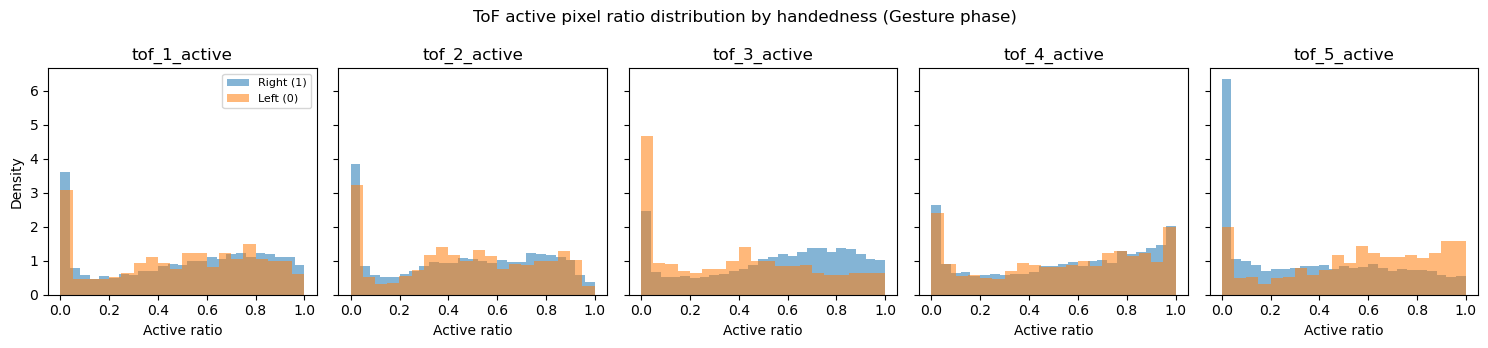

In [14]:
# 3a. Compare sequence-level THM and ToF distributions by handedness (0 = Left, 1 = Right)
gest_hand_tof = seq_tof.merge(seq[["sequence_id", "handedness", "orientation"]], on="sequence_id", how="left")

print("Sequence-level delta THM (°C) in Gesture phase by handedness (0=Left, 1=Right):")
display(seq_thm.groupby("handedness")[thm_cols].agg(["mean", "median"]).round(2))

print("Sequence-level ToF active ratio in Gesture phase by handedness (0=Left, 1=Right):")
display(gest_hand_tof.groupby("handedness")[active_cols].agg(["mean", "median"]).round(3))

print("Sequence-level ToF mean distance (mm) in Gesture phase by handedness (0=Left, 1=Right):")
display(gest_hand_tof.groupby("handedness")[mean_cols].agg(["mean", "median"]).round(1))

# Plot ToF active ratio distribution by handedness across the 5 sensors
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), sharey=True)
for idx, col in enumerate(active_cols):
    right_vals = gest_hand_tof.loc[gest_hand_tof["handedness"] == 1, col].dropna()
    left_vals = gest_hand_tof.loc[gest_hand_tof["handedness"] == 0, col].dropna()

    axes[idx].hist(right_vals, bins=25, density=True, alpha=0.55, label="Right (1)")
    axes[idx].hist(left_vals, bins=20, density=True, alpha=0.55, label="Left (0)")
    axes[idx].set_title(col)
    axes[idx].set_xlabel("Active ratio")
    if idx == 0:
        axes[idx].set_ylabel("Density")
        axes[idx].legend(fontsize=8)

fig.suptitle("ToF active pixel ratio distribution by handedness (Gesture phase)")
plt.tight_layout()
plt.savefig(FIG_DIR / "tof_handedness_dist.png", dpi=150)
plt.show()

In [15]:
# 3b. Compare THM and ToF signals of BFRB gestures across the 4 body orientations
target_thm = seq_thm[seq_thm["sequence_type"] == "Target"]
target_tof = gest_hand_tof[gest_hand_tof["sequence_type"] == "Target"]

print("Mean temperature change (°C) of BFRB gestures by orientation:")
display(target_thm.groupby("orientation")[thm_cols + ["max_delta_thm"]].mean().round(2))

print("Mean ToF active pixel fraction of BFRB gestures by orientation:")
display(target_tof.groupby("orientation")[active_cols + ["mean_active_all"]].mean().round(2))

print("Mean ToF object distance (mm) of BFRB gestures by orientation:")
display(target_tof.groupby("orientation")[mean_cols + ["min_dist_all"]].mean().round(1))

Mean temperature change (°C) of BFRB gestures by orientation:


,thm_1,thm_2,thm_3,thm_4,thm_5,max_delta_thm
orientation,,,,,,
Lie on Back,2.91,3.49,3.36,1.83,0.79,4.66
Lie on Side - Non Dominant,1.24,2.53,1.80,0.60,0.35,3.14
Seated Lean Non Dom - FACE DOWN,2.48,4.05,2.92,0.90,1.58,4.53
Seated Straight,3.25,3.75,3.47,1.97,1.58,4.66


Mean ToF active pixel fraction of BFRB gestures by orientation:


,tof_1_active,tof_2_active,tof_3_active,tof_4_active,tof_5_active,mean_active_all
orientation,,,,,,
Lie on Back,0.57,0.53,0.65,0.58,0.38,0.54
Lie on Side - Non Dominant,0.60,0.56,0.62,0.62,0.45,0.57
Seated Lean Non Dom - FACE DOWN,0.72,0.70,0.70,0.76,0.61,0.70
Seated Straight,0.55,0.54,0.60,0.57,0.36,0.53


Mean ToF object distance (mm) of BFRB gestures by orientation:


,tof_1_mean,tof_2_mean,tof_3_mean,tof_4_mean,tof_5_mean,min_dist_all
orientation,,,,,,
Lie on Back,115.4,102.7,101.2,116.6,132.3,46.1
Lie on Side - Non Dominant,122.6,121.0,97.4,104.5,132.8,34.4
Seated Lean Non Dom - FACE DOWN,97.5,84.5,92.6,110.2,108.9,41.4
Seated Straight,120.2,99.3,107.2,127.3,137.9,50.7


Sequences with partial missing values (some rows):
  thm_2 | SEQ_044963 (subject=SUBJ_055211, len=49) | NaN count=35 at steps 14..48
  thm_5 | SEQ_062104 (subject=SUBJ_053217, len=49) | NaN count=38 at steps 11..48
  tof_5 | SEQ_062104 (subject=SUBJ_053217, len=49) | NaN count=38 at steps 11..48


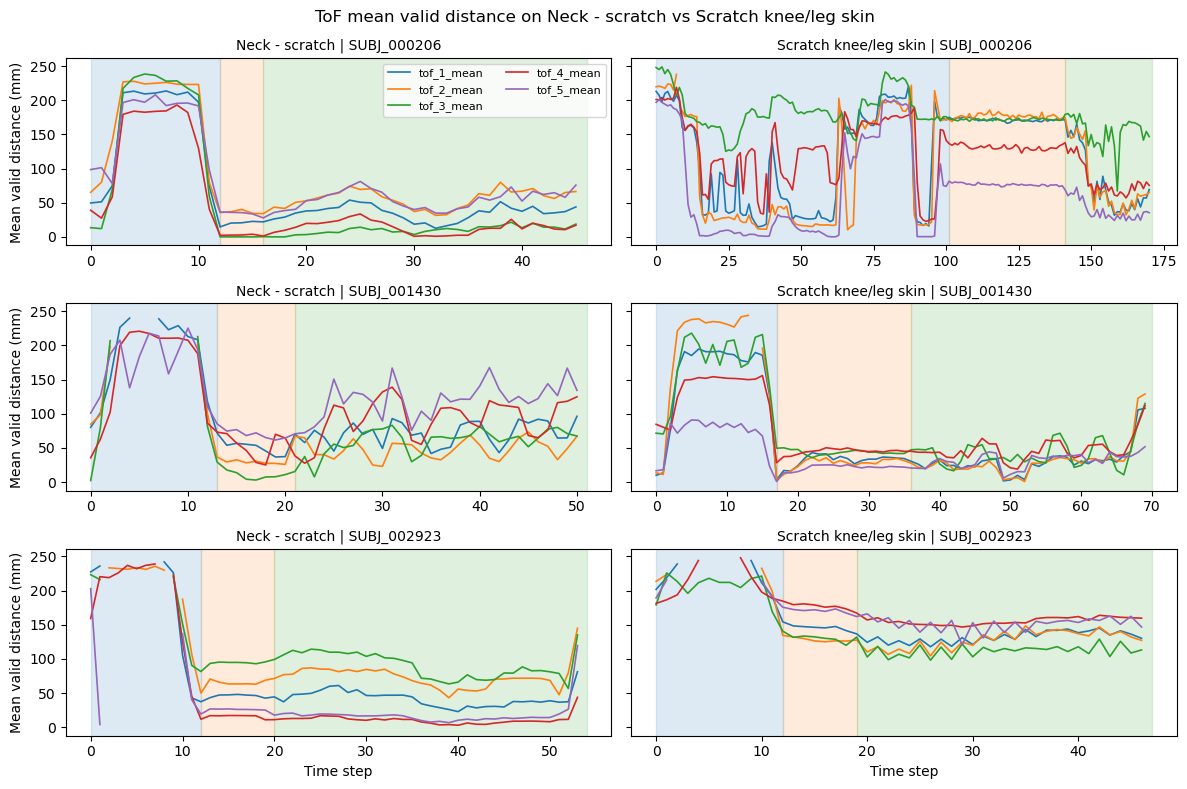

In [16]:
# 3c. Inspect partially missing sequences and plot ToF time-series on Neck - scratch vs Scratch knee/leg skin
print("Sequences with partial missing values (some rows):")
for name, col in [("thm_2", "thm_2"), ("thm_5", "thm_5"), ("tof_5", "tof_5_v0")]:
    na_frac = train[col].isna().groupby(train["sequence_id"]).mean()
    for sid in na_frac[(na_frac > 0) & (na_frac < 1)].index:
        sub = train[train["sequence_id"] == sid].sort_values("sequence_counter")
        na_steps = sub.loc[sub[col].isna(), "sequence_counter"].tolist()
        print(
            f"  {name} | {sid} (subject={sub['subject'].iloc[0]}, len={len(sub)}) | "
            f"NaN count={len(na_steps)} at steps {min(na_steps)}..{max(na_steps)}"
        )

# Time-series comparison on the confused pair: Neck - scratch vs Scratch knee/leg skin
pair = ["Neck - scratch", "Scratch knee/leg skin"]
pick = seq[
    seq["gesture"].isin(pair)
    & (seq["orientation"] == "Seated Lean Non Dom - FACE DOWN")
]
n_gestures = pick.groupby("subject")["gesture"].nunique()
subjects = n_gestures[n_gestures == 2].index[:3]

phase_colors = {
    "Relaxes and moves hand to target location": "tab:blue",
    "Moves hand to target location": "tab:blue",
    "Hand at target location": "tab:orange",
    "Performs gesture": "tab:green",
}

fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharey=True)
for row, subj in enumerate(subjects):
    for col, g in enumerate(pair):
        sid = pick.loc[(pick["subject"] == subj) & (pick["gesture"] == g), "sequence_id"].iloc[0]
        s = train[train["sequence_id"] == sid].sort_values("sequence_counter")
        s_tof = tof_feat[tof_feat["sequence_id"] == sid].sort_values("sequence_counter")
        ax = axes[row, col]

        for beh, part in s.groupby("behavior"):
            ax.axvspan(
                part["sequence_counter"].min(),
                part["sequence_counter"].max() + 1,
                color=phase_colors[beh],
                alpha=0.15,
            )
        for i in range(1, 6):
            ax.plot(s_tof["sequence_counter"], s_tof[f"tof_{i}_mean"], label=f"tof_{i}_mean", linewidth=1.2)
        ax.set_title(f"{g} | {subj}", fontsize=10)

axes[0, 0].legend(loc="upper right", ncol=2, fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Time step")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean valid distance (mm)")
fig.suptitle("ToF mean valid distance on Neck - scratch vs Scratch knee/leg skin")
plt.tight_layout()
plt.savefig(FIG_DIR / "tof_signal_neck_vs_knee.png", dpi=150)
plt.show()

## Tổng kết: tay thuận, tư thế cơ thể và chuỗi thời gian
- **Theo tay thuận (`handedness`):** Không giống cảm biến gia tốc IMU bị đảo dấu trục X khi đổi tay đeo đồng hồ, mức độ tăng nhiệt (`delta_thm`), tỉ lệ pixel hoạt động (`tof_active`) và khoảng cách trung bình (`tof_mean`) có phân phối tương đồng giữa nhóm thuận tay phải (`1`) và thuận tay trái (`0`); chỉ có sự dịch chuyển nhẹ về tỉ lệ hoạt động giữa các cảm biến cạnh bên do góc tiếp xúc của cổ tay trái/phải với khuôn mặt.
- **Theo tư thế cơ thể (`orientation`):** Trong khi tín hiệu trọng lực của IMU biến đổi mạnh theo 4 tư thế (Ngồi thẳng, Ngồi cúi mặt, Nằm ngửa, Nằm nghiêng), tín hiệu Nhiệt và ToF trong pha `Gesture` của nhóm BFRB duy trì tính ổn định cao ở cả 4 tư thế (nhiệt độ đều tăng mạnh và tỉ lệ pixel hoạt động/khoảng cách gần vật cản luôn tách biệt với nhóm không chạm người). Điều này giúp THM và ToF trở thành nguồn đặc trưng bổ trợ quan trọng cho IMU khi người đeo thay đổi tư thế.
- **Dữ liệu khuyết cục bộ (`some rows`):** Các chuỗi bị thiếu một phần ở `thm_2`, `thm_5` và `tof_5` có các bước `NaN` xuất hiện thành từng đoạn ngắn hoặc rải rác bên trong chuỗi, do đó có thể phục hồi an toàn bằng nội suy theo thời gian (`ffill` / `bfill`) trong phạm vi từng `sequence_id`.
- **Đối chiếu chuỗi thời gian cặp cử chỉ dễ nhầm (*Neck - scratch* vs *Scratch knee/leg skin*):** Khi bước vào pha `Performs gesture` (vùng màu xanh lá), khoảng cách `tof_1..5_mean` giảm sâu đồng loạt ở cả 5 cảm biến (kể cả `tof_5`) đối với *Scratch knee/leg skin*, trong khi với *Neck - scratch* khoảng cách giảm sâu nhất ở `tof_3` và giữ khoảng cách xa hơn ở `tof_5`, cung cấp dấu hiệu rõ ràng để phân tách hai cử chỉ có cùng biên độ chuyển động gãi.

## Tóm tắt phát hiện và quyết định tiền xử lý

### 1. Tóm tắt các phát hiện chính từ EDA
1. **Đặc tính vật lý và 2 dạng lỗi của cảm biến nhiệt (`thm_1..5`):**
   - Nhiệt độ hợp lệ nằm trong dải **21,96 – 39,59 °C** (`1a`), nhưng nhiệt độ nền 5 bước đầu chuỗi chênh lệch lớn giữa các người đeo (**23,86 – 32,68 °C**, `1b`).
   - Có **153/8.151 chuỗi** xuất hiện giá trị `< 20 °C` (`1e`, `1e-2`), chia làm 2 dạng lỗi khác bản chất:
     - **Cảm biến chết cứng ở 0 °C:** Toàn bộ 102 chuỗi của `SUBJ_028998` có `thm_3 = 0.0 °C` không đổi (`std = 0.0`).
     - **Cảm biến lệch mốc chuẩn nhưng vẫn nhạy nhiệt:** 51 chuỗi của `SUBJ_036405` có `thm_1` bị tụt nền xuống `-0,37..18,9 °C` nhưng vẫn tăng nhiệt bình thường (`range` đạt `1,6–4,75 °C`) khi chạm mặt/cổ.
   - Tỉ lệ mất toàn bộ chuỗi (`all_NaN`) là **~0,97–1,10%** ở `thm_1..4` và tăng lên **4,84%** ở `thm_5`.
2. **Đặc trưng nhiệt phân tách các nhóm cử chỉ (`1c`, `1d`, `1f`):**
   - Trừ nhiệt độ nền đầu chuỗi (`delta_thm = thm - baseline_5_bước_đầu`) giúp loại bỏ độ lệch cơ địa và tách rõ phân phối `Target` với `Non-Target` (`1f`).
   - Nhóm BFRB làm nóng lệch về cụm cảm biến `thm_1..3`, trong khi nhóm chạm chân làm nóng đều cả 5 cảm biến (đặc biệt là `thm_5` tăng `+1,57..+1,94 °C`, `1c`).
3. **Bản chất mã `-1` và các trạng thái của lưới 8×8 ToF (`2a`, `2b`):**
   - Khi có vật cản (`pixel != -1`), khoảng cách đo được nằm trong khoảng **0 – 249 mm** (trung vị **90 – 108 mm**, phân vị 99% là **243 – 245 mm**, `2a`).
   - Đa số các bước thời gian (**74,05% – 84,69%**) ở trạng thái trộn lẫn (`mixed`: một phần lưới 8×8 thấy vật cản, phần còn lại là `-1`), **9,55% – 22,41%** số dòng hoàn toàn không thấy vật cản (`all_-1`), và **1,08%** (`tof_1..4`) đến **5,24%** (`tof_5`) bị mất tín hiệu hoàn toàn (`all_NaN`, `2b`).
4. **Không gian đặc trưng ToF và bất đối xứng góc phần tư (`2c`, `2d`, `2e`, `2f`, `3c`):**
   - Khi chuyển từ `Transition` sang `Gesture` ở nhóm BFRB, tỉ lệ pixel hoạt động tăng mạnh (từ **0,34–0,46** lên **0,58–0,64**) và khoảng cách gần nhất giảm sâu (từ **~88–92 mm** xuống **58,6–76,1 mm**, `2c`).
   - **Phân biệt BFRB với Chạm chân:** Cử chỉ chạm chân có `tof_5_active` cao (**0,69–0,70**) và khoảng cách `tof_5_mean` rất gần (**68,5–70,3 mm**); ngược lại cử chỉ BFRB có `tof_5_active` thấp hơn (**0,30–0,62**) và khoảng cách gần nhất tập trung ở `tof_3` (**59,2–80,0 mm** cho vùng cổ/má) hoặc `tof_2` (**78,4–102,9 mm** cho vùng trán/tai, `2d`, `3c`).
   - Trên lưới 8×8 (`2f`), mật độ bắt vật cản lệch hướng rõ rệt theo vị trí lắp cảm biến: `tof_1, 2, 4` lệch sang **nửa phải (`Q2, Q4`)**, `tof_3` lệch sang **nửa trái (`Q1, Q3`)**, và `tof_5` lệch lên **nửa trên (`Q1, Q2`)**.
   - Các đặc trưng THM và ToF bất biến với tay thuận (`3a`) và tư thế cơ thể (`3b`), không cần lật trục như IMU.

---

### 2. Quyết định tiền xử lý và tạo đặc trưng (trong `src/preprocess_tof.py`)

Mọi bước xử lý dưới đây đều được thực hiện **độc lập trên từng chuỗi (`sequence_id`)**, giữ nguyên số dòng và chạy đồng nhất cho cả tập train lẫn tập test:

| Làm gì? (Bước xử lý / Đặc trưng) | Vì sao? (Cơ sở từ phát hiện EDA) | Kiểm chứng thế nào? (Số liệu / Biểu đồ đối chứng) |
| :--- | :--- | :--- |
| **1. Xử lý lỗi phần cứng & điền khuyết Nhiệt độ (`thm_1..5`)**<br>- Tạo cờ `thm_{i}_broken` báo kênh nhiệt bị `NaN` hoặc chết cứng ở `0 °C` (`std < 1e-4` và `mean < 20 °C`).<br>- Chuyển các chuỗi chết cứng ở `0 °C` thành `NaN`, sau đó nội suy `ffill/bfill` trong từng `sequence_id`. | - Loại bỏ 102 chuỗi `thm_3 = 0.0 °C` cố định của `SUBJ_028998` nhưng **không xóa** 51 chuỗi lệch mốc chuẩn của `SUBJ_036405` vì kênh này vẫn ghi nhận biến thiên nhiệt độ thực tế.<br>- Xử lý các chuỗi khuyết cục bộ vài bước thời gian mà không làm rò rỉ dữ liệu giữa các chuỗi. | - Bảng `1e` và `1e-2` (phân tách `std = 0.0` của `SUBJ_028998` và `std = 0.20..1.78` của `SUBJ_036405`).<br>- Bảng kiểm tra chuỗi thiếu cục bộ ở mục `3c`. |
| **2. Chuẩn hóa nhiệt độ theo đầu chuỗi & nội suy chéo kênh**<br>- Tính `thm_{i}_delta = thm_{i} - mean(thm_{i}[counter < 5])` trên từng chuỗi.<br>- Nếu kênh bị hỏng cả chuỗi (`all_NaN`), điền `thm_{i}_delta` bằng trung bình `delta` của các kênh nhiệt còn sống trên cùng dòng.<br>- Hiệu chỉnh lại nhiệt độ tuyệt đối `thm_{i}` cho các kênh hỏng/lệch nền bằng `healthy_baseline + thm_{i}_delta`. | - Khử triệt để độ lệch nhiệt độ nền giữa các người đeo (`23,9 – 32,7 °C`) và tự động khử hằng số lệch chuẩn của `SUBJ_036405`.<br>- Cứu được các chuỗi mất hoàn toàn `thm_5` (4,84% tập train) hoặc hỏng `thm_3` bằng nhiệt độ của các cảm biến lân cận trên cùng cổ tay mà không cần học tham số toàn cục. | - Bảng `1b` (độ lệch baseline giữa các subject).<br>- Biểu đồ Histogram kép `1f` (`raw_mean_thm` bị chồng lấn vs `mean_delta_thm` tách biệt rõ `Target` và `Non-Target`). |
| **3. Tạo đặc trưng tổng hợp & đối xứng không gian Nhiệt**<br>- Tính `thm_delta_mean`, `thm_delta_std`, `thm_delta_max`, `thm_delta_min`, tốc độ tăng nhiệt `thm_delta_diff`.<br>- Tính hiệu số `thm_123_vs_45_delta = mean(thm_1..3_delta) - mean(thm_4..5_delta)`. | - Nắm bắt biên độ và tốc độ truyền nhiệt khi bàn tay tiếp xúc cơ thể.<br>- `thm_123_vs_45_delta` giúp phân biệt cử chỉ BFRB vùng đầu/mặt (chỉ làm nóng mạnh `thm_1..3`) với cử chỉ chạm chân (làm nóng đồng đều cả `thm_4..5`). | - Bảng `1c` và Boxplot `1d` (độ tăng nhiệt theo từng kênh của 18 cử chỉ). |
| **4. Tách biệt mã `-1` và `NaN` trên từng cảm biến ToF (`tof_1..5`)**<br>- Tạo cờ `tof_{i}_broken` khi cả 64 pixel là `NaN`.<br>- Thay `-1` bằng `NaN` khi tính khoảng cách vật lý; sau đó gán trần khoảng cách xa **`255.0 mm`** (và `std = 0.0`) cho các dòng không có vật cản (`all_-1`) cũng như các pixel `-1` gốc. | - `74%–85%` số dòng có cả pixel `-1` và pixel hợp lệ (`0..249 mm`); tính trung bình trực tiếp trên `-1` sẽ làm sai lệch khoảng cách vật lý.<br>- Giá trị `255.0 mm` nằm ngay trên ngưỡng đo tối đa (`249 mm`), thể hiện đúng ý nghĩa vật lý "vật ở xa ngoài tầm nhìn" và liên tục về mặt số học. | - Bảng phân phối khoảng cách `2a` (`max = 249 mm`, `99% = 245 mm`).<br>- Bảng tỷ lệ 4 trạng thái lưới 8×8 ở mục `2b`. |
| **5. Nén mỗi lưới 8×8 ToF thành các thống kê & độ lệch góc phần tư**<br>- Tính cho mỗi cảm biến `i=1..5`: tỉ lệ pixel hoạt động `tof_{i}_active` ($0..1$), khoảng cách `mean`, `std`, `min`, `max`.<br>- Chia lưới 8×8 thành 4 góc 4×4 (`Q1..Q4`), tính độ lệch Phải–Trái `tof_{i}_lr_diff` và Trên–Dưới `tof_{i}_tb_diff`. | - Cô đọng 320 cột pixel nhiễu thành các đại lượng vật lý đại diện cho diện tích che phủ, khoảng cách tiếp xúc và độ nghiêng bề mặt.<br>- Khai thác tính định hướng không gian của từng mắt ToF trên cổ tay (`tof_1,2,4` lệch phải, `tof_3` lệch trái, `tof_5` lệch trên). | - Bảng `2c` (sự thay đổi `active`, `mean`, `min` giữa pha `Transition` và `Gesture`).<br>- Bảng thống kê `Q1..Q4` và Heatmap 5×8×8 ở mục `2f`. |
| **6. Tạo đặc trưng tương quan chéo 5 cảm biến ToF & động học**<br>- Tính `tof_active_mean`, `tof_active_std`, `tof_mean_dist_all`, `tof_min_dist_all` và vận tốc tiếp cận `tof_min_dist_diff`.<br>- Tính `tof_5_vs_1234_active` và `tof_5_vs_3_mean`. | - Đặt mỗi bước thời gian vào không gian phân cụm 2 chiều (`active` vs `min_dist`).<br>- `tof_5_vs_1234_active` và `tof_5_vs_3_mean` giải quyết trực tiếp sự nhập nhằng giữa nhóm chạm chân (`tof_5` hoạt động mạnh và ở rất gần ~69 mm) với nhóm BFRB vùng cổ/mặt (`tof_3` gần nhất ~59 mm, `tof_5` ở xa). | - Bảng `2d`, biểu đồ Scatter 2D `2e` và biểu đồ chuỗi thời gian so sánh *Neck - scratch* vs *Scratch knee/leg skin* ở mục `3c`. |